# Explore the ECB AAA yield curve (main series)

ECB euro-area AAA government bonds, spot rates in percent, continuous compounding, daily (`load_curve("AAA")`). This is the series used for all models.

Same exploration for each of the three datasets (`01_ecb_aaa`, `02_bundesbank_de`, `03_fed_us`).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from scenario_lab.data import load_curve
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"  # undo IDE dark-theme recolouring
warnings.filterwarnings("ignore")  # statsmodels API/table-range warnings; KPSS p is clipped to [0.01, 0.1]

d = load_curve("AAA")
MATS = [1, 2, 5, 10, 20, 30]
print(d.shape, d.index.min().date(), d.index.max().date(), "NaN:", int(d.isna().sum().sum()))
d.describe().round(2)

(5678, 6) 2004-09-06 2026-11-19 NaN: 0


,1Y,2Y,5Y,10Y,20Y,30Y
count,5678.00,5678.00,5678.00,5678.00,5678.00,5678.00
mean,1.02,1.10,1.46,2.04,2.48,2.53
std,1.62,1.59,1.55,1.54,1.52,1.47
min,-0.91,-0.97,-1.00,-0.82,-0.51,-0.43
25%,-0.59,-0.55,-0.14,0.48,1.06,1.26
50%,0.53,0.82,1.73,2.36,2.72,2.61
75%,2.38,2.45,2.69,3.40,3.81,3.84
max,4.54,4.71,4.73,4.78,4.98,5.18


## 1. History of each maturity

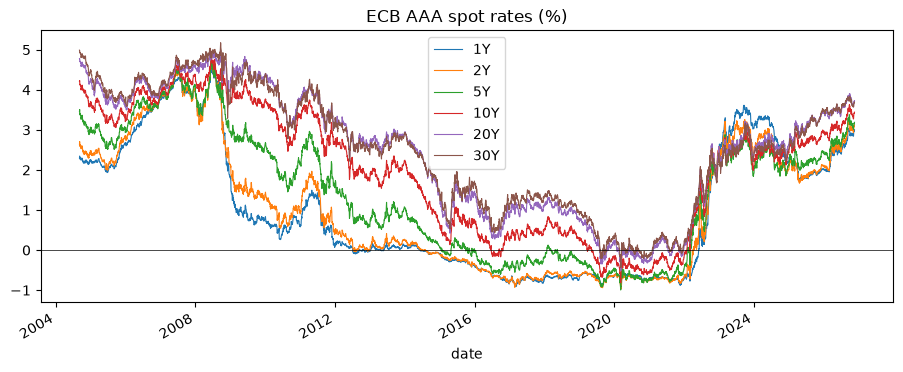

In [2]:
d.plot(figsize=(11, 4), lw=0.8, title="ECB AAA spot rates (%)"); plt.axhline(0, c="k", lw=0.5); plt.show()

## 2. Curve shapes on selected dates

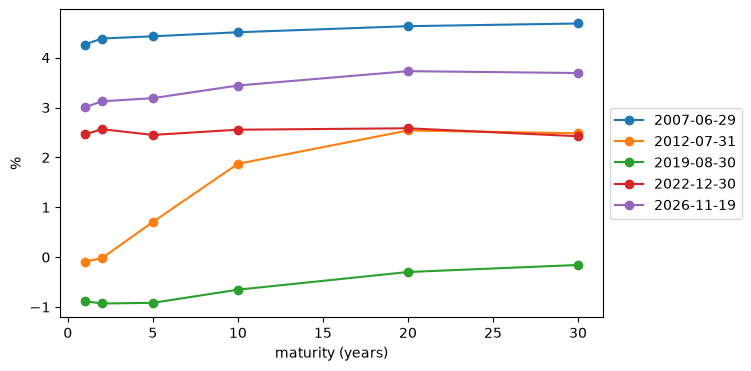

In [3]:
dates = ["2007-06-29", "2012-07-31", "2019-08-30", "2022-12-30", "2100-01-01"]      # last entry = latest available day
fig, ax = plt.subplots(figsize=(7, 4))
for dt in dates:
    r = d.loc[:dt].iloc[-1]
    ax.plot(MATS, r.values, marker="o", label=str(r.name.date()))
ax.set(xlabel="maturity (years)", ylabel="%"); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.show()

## 3. Rate changes (weekly, Friday-to-Friday) and cross-maturity correlation

In [4]:
w = d.resample("W-FRI").last()
dw = w.diff().dropna()
print(dw.describe().round(3).loc[["std", "min", "max"]])
print("excess kurtosis:\n", dw.kurt().round(2))
print(dw.corr().round(2))

        1Y     2Y     5Y    10Y    20Y    30Y
std  0.069  0.087  0.093  0.092  0.097  0.107
min -0.608 -0.569 -0.436 -0.361 -0.439 -0.702
max  0.388  0.377  0.417  0.404  0.413  0.432
excess kurtosis:
 1Y     11.12
2Y      5.47
5Y      2.26
10Y     1.07
20Y     1.43
30Y     3.16
dtype: float64
       1Y    2Y    5Y   10Y   20Y   30Y
1Y   1.00  0.92  0.73  0.56  0.43  0.34
2Y   0.92  1.00  0.89  0.70  0.55  0.45
5Y   0.73  0.89  1.00  0.91  0.75  0.64
10Y  0.56  0.70  0.91  1.00  0.92  0.81
20Y  0.43  0.55  0.75  0.92  1.00  0.94
30Y  0.34  0.45  0.64  0.81  0.94  1.00


## 4. Stationarity: levels vs weekly changes

ADF null: unit root. KPSS null: stationary. Read them together; ADF has low power on persistent series.

In [5]:
rows = []
for name, s in [("level", w), ("change", dw)]:
    for c in s.columns:
        rows.append((name, c, adfuller(s[c], autolag="AIC")[1], kpss(s[c], regression="c", nlags="auto")[1]))
res = pd.DataFrame(rows, columns=["series", "mat", "ADF p", "KPSS p"]).round(3)
res.pivot(index="mat", columns="series", values=["ADF p", "KPSS p"]).reindex([f"{m}Y" for m in MATS])

ADF p        KPSS p      
series change  level change level
mat                              
1Y        0.0  0.626  0.074  0.01
2Y        0.0  0.731  0.035  0.01
5Y        0.0  0.718  0.032  0.01
10Y       0.0  0.646  0.041  0.01
20Y       0.0  0.572  0.053  0.01
30Y       0.0  0.607  0.050  0.01

## 5. Volatility clustering: rolling 1-year std of weekly changes

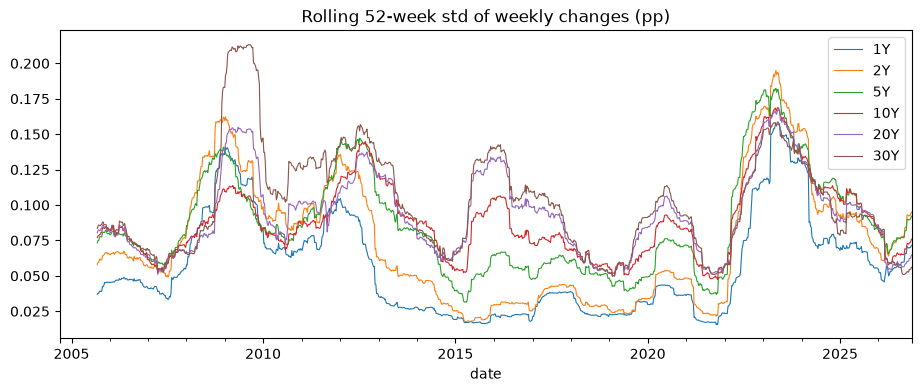

In [6]:
dw.rolling(52).std().plot(figsize=(11, 4), lw=0.8, title="Rolling 52-week std of weekly changes (pp)"); plt.show()

## 6. AAA vs all-issuers

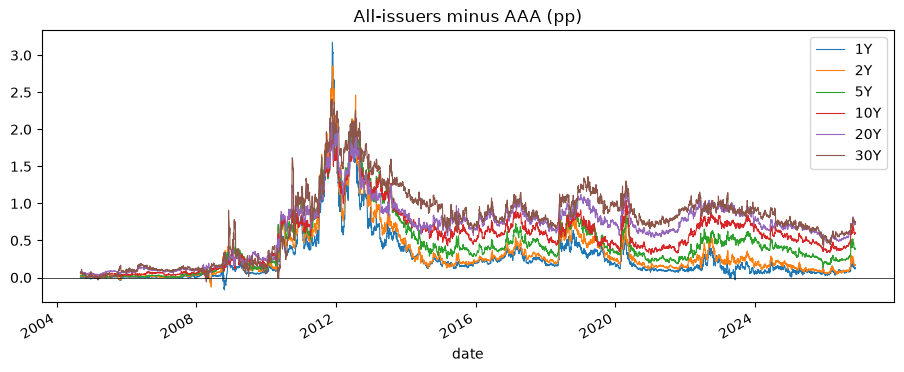

In [7]:
allc = load_curve("ALL")
(allc - d).plot(figsize=(11, 4), lw=0.8, title="All-issuers minus AAA (pp)"); plt.axhline(0, c="k", lw=0.5); plt.show()

## Observations

- **Sample:** 5,678 days from 2004-09 to 2026-11 (22.2 years), rates from -1.0% to 5.2%.
- **Weekly changes:** std 0.07 pp (1Y) to 0.11 pp (30Y). Excess kurtosis is 11 at 1Y and 5.5 at 2Y, near 1-3 elsewhere: fat tails mostly at the short end.
- **Stationarity:** ADF does not reject a unit root in the levels (p 0.57-0.73) and rejects it for the weekly changes (p ~ 0); KPSS rejects stationary levels (p = 0.01) and is borderline for the changes (p 0.03-0.07). Model changes, not levels.
- **Volatility clustering** is clear in the rolling std (low in 2012-2019, high in 2022-23).
- **Maturity correlations** of weekly changes are high between neighbours (0.9) and fall to 0.3-0.5 between 1Y and 30Y: a few factors drive the curve, which is what the PCA step of the models exploits.